<h1>Projeto 01 de Inteligência Artificial: agente de rotas para comida local</h1>
<p>Licenciatura em Engenharia de Sistemas Informáticos, UPCA, 2026-27. Grupo G13.</p>
<ul>
<li>Diogo Alexandre Alves da Silva, nº 31504</li>
<li>Gonçalo Rodrigues, nº 31507</li>
<li>Rui Barbosa, nº 31515</li>
</ul>

<h2>1. Introdução</h2>
<p>O tema é <b>Comida Local</b>: uma plataforma digital que liga pequenos produtores, clientes e um centro de recolha (armazém). Uma frota de veículos recolhe os produtos nos produtores, leva os ao armazém e entrega os nos locais escolhidos pelos clientes.</p>
<h3>Motivação</h3>
<p>A procura de comida local cresce na UE, mas os pequenos produtores enfrentam custos logísticos elevados. Cadeias curtas reduzem emissões e desperdício, desde que a logística seja eficiente: é preciso escolher rotas de recolha e entrega que respeitem as janelas de tempo de cada pedido, a capacidade dos veículos e as regras do armazém.</p>
<h3>Objetivo</h3>
<p>Desenvolver um agente inteligente que planeie essas rotas, aplicando e comparando:</p>
<ul>
<li>pesquisa informada (Greedy e A*, com duas heurísticas);</li>
<li>pesquisa local (Hill Climbing sobre a solução do Greedy);</li>
<li>problemas de satisfação de restrições (CSP).</li>
</ul>
<h3>Estrutura do projeto</h3>
<ul>
<li><code>01_Project01_G13.ipynb</code> (este notebook): modelação, algoritmos, resultados e conclusão.</li>
<li><code>02_eda_tiny.ipynb</code> e <code>02_eda_small.ipynb</code>: análise exploratória dos dois datasets (o mesmo código, só muda a pasta).</li>
<li><code>model.py</code>: regras, entidades, ações, função de custo, simulador e verificador de viabilidade.</li>
<li><code>informed.py</code> (Greedy, A*, heurísticas), <code>local_search.py</code> (Hill Climbing), <code>csp.py</code> (CSP) e <code>agent.py</code> (agente completo).</li>
<li><code>data_tiny/</code> e <code>data_small/</code>: datasets em CSV, incluindo o <code>rules.csv</code>.</li>
</ul>
<p>Os módulos <code>.py</code> concentram o código e este notebook importa os e documenta cada passo, com os resultados da execução.</p>

<h2>2. Análise exploratória (resumo)</h2>
<p>A análise completa está em <code>02_eda_tiny.ipynb</code> e <code>02_eda_small.ipynb</code>.</p>
<table>
<tr><th></th><th>tiny</th><th>small</th></tr>
<tr><td>produtores / centros / veículos</td><td>3 / 1 / 2</td><td>6 / 1 / 2</td></tr>
<tr><td>locais de entrega / encomendas / pedidos</td><td>5 / 12 / 40</td><td>7 / 25 / 80</td></tr>
<tr><td>carga total / capacidade da frota</td><td>270 kg / 350 kg</td><td>580 kg / 550 kg</td></tr>
<tr><td>veículos (capacidade, refrigerado)</td><td>150 kg sim, 200 kg não</td><td>250 kg sim, 300 kg não</td></tr>
<tr><td>horizonte</td><td>30 e 31/10/2026</td><td>30 e 31/10/2026</td></tr>
<tr><td>pedidos entregues no dia seguinte</td><td>10</td><td>20</td></tr>
<tr><td>grupos temporais independentes</td><td>1 (40 pedidos)</td><td>1 (80 pedidos)</td></tr>
</table>
<ul>
<li><b>Regras (<code>rules.csv</code>):</b> todo o produto passa pelo armazém; 10 min de serviço em cada paragem de recolha ou entrega; 15 min de manuseamento no armazém; no máximo 24 h no armazém; as janelas limitam o início do serviço; 45 km/h e fator de estrada 1.3 (já usados na matriz).</li>
<li><b>Integridade:</b> sem valores em falta, duplicados ou referências inválidas; <code>weight_kg</code> = <code>quantity × unit_weight_kg</code>.</li>
<li><b>Janelas:</b> coerentes e dentro dos 2 dias. O intervalo entre o fim da recolha e o início da entrega vai de -1.5 h a 23.75 h, sempre abaixo do limite de 24 h no armazém.</li>
<li><b>Capacidade:</b> passa a ser uma restrição ativa. No tiny, a 30/10 há 166.9 kg para recolher, mais do que cabe no veículo 1; no small a carga total excede a frota e são obrigatórias várias viagens.</li>
<li><b>Refrigeração:</b> há 1 veículo refrigerado em 2, mas nenhum produto está marcado como exigindo frio (o <code>products.csv</code> não tem essa coluna). A restrição está no modelo, mas não está ativa nestes datasets.</li>
<li><b>Velocidade:</b> veículos, matriz e <code>rules.csv</code> dão todos 45 km/h, por isso usam se os tempos da matriz.</li>
<li><b>Matriz:</b> simétrica, fator 1.3 e desigualdade triangular (no small, a menos de arredondamentos de 0.01 km). Há pontos diferentes com as mesmas coordenadas: dois locais de entrega no tiny; no small, o produtor 4 fica no próprio centro de recolha.</li>
<li><b>Viabilidade:</b> no melhor caso todos os pedidos cumprem a janela de entrega (folga mínima de 90 min); não há atrasos inevitáveis.</li>
<li><b>Estrutura temporal:</b> os pedidos já não se separam em grupos independentes. O problema tem de ser resolvido de uma vez, com 40 (tiny) ou 80 (small) pedidos.</li>
</ul>

<h2>3. Modelação</h2>
<h3>Terminologia e problema</h3>
<p>Uma <b>encomenda</b> tem um ou mais <b>pedidos</b>; um pedido é uma linha de <code>order_items</code> (um produto de um produtor, com peso, janela de recolha e janela de entrega) e é a unidade de planeamento (classe <code>Request</code>). O problema é escolher rotas para os veículos que sirvam todos os pedidos com o menor custo, respeitando as restrições.</p>
<h3>Regras e interpretações</h3>
<p>As regras são lidas do <code>rules.csv</code> por <code>load_rules</code> (classe <code>Rules</code>); se o ficheiro não existir, usam se valores por omissão (10 min de serviço, 10 min no armazém, sem limite no armazém, janelas sobre o início do serviço). Algumas regras são ambíguas e foram interpretadas assim:</p>
<ul>
<li><b>Paragem.</b> O serviço de 10 min (<code>stop_service_min</code>) é cobrado <b>por paragem</b>, não por artigo. Uma paragem são ações seguidas do mesmo veículo no mesmo <code>location_id</code>. Uma ação junta se à paragem em curso se o produto já estava pronto no início dessa paragem (na recolha: a janela já tinha aberto; na entrega: a janela de entrega já tinha aberto); se não, começa um novo serviço. Dois pontos diferentes com as mesmas coordenadas são paragens diferentes, a 0 km.</li>
<li><b>Armazém.</b> Uma paragem no armazém demora 15 min (<code>warehouse_handling_min</code>) e cobre a descarga e a carga feitas nessa paragem. A alternativa seria 15 + 15 min quando há descarga e carga; escolheu se uma só operação porque o texto da regra é "time to unload (and to load) a vehicle".</li>
<li><b>Chegada ao armazém</b> é o fim da descarga. O limite de 24 h (<code>max_warehouse_dwell_h</code>) é uma restrição hard entre essa chegada e o início da carga. Um veículo que descarrega e volta a carregar os seus próprios produtos na mesma paragem não os larga (ficam a bordo).</li>
<li><b>Janelas</b> (<code>window_semantics = service_start</code>): limitam o início do serviço. O modelo também aceita <code>service_end</code> (desloca as janelas de S).</li>
<li><b>Fluxo:</b> só se suporta <code>producer&gt;warehouse&gt;delivery_location</code> (outro valor lança <code>NotImplementedError</code>).</li>
<li><b>Tempo:</b> a origem é a meia noite de <code>start_date</code> (30/10); os veículos partem do centro no instante 0 e regressam no fim. A velocidade e o fator de estrada só são informativos, porque a matriz já os inclui.</li>
<li><b>Frio:</b> <code>Request.cold</code> vem de uma coluna de <code>products</code> (por exemplo <code>requires_refrigeration</code>) se existir; <code>Vehicle.refrigerated</code> vem de <code>vehicles.csv</code>. Um pedido que exige frio só pode ir em veículos refrigerados.</li>
<li><b>Não modelado:</b> a capacidade do centro (5000 kg, nunca limitativa) e um limite ao tempo que um produto passa a bordo.</li>
</ul>
<h3>Restrições</h3>
<ul>
<li><b>Hard:</b> recolha com início dentro de [<code>availability_start</code>, <code>availability_end</code>]; entrega não antes de <code>delivery_start</code>; capacidade do veículo; frio; cada pedido recolhido e entregue uma vez; todo o produto passa pelo armazém; só se carrega no armazém o que já lá chegou; no máximo 24 h no armazém.</li>
<li><b>Soft:</b> entrega até <code>delivery_end</code>, com penalização.</li>
</ul>
<h3>Estado, ações e custo</h3>
<p><b>Estado</b> (<code>State</code>): para cada veículo, a localização, o instante em que fica livre, a carga e o início do serviço da paragem em curso; para cada pedido, a fase (pendente, cru a bordo de v, no armazém, a bordo de v a caminho do cliente, entregue), o instante em que chegou ao armazém e o veículo que o descarregou.</p>
<p><b>Ações</b> de um veículo: <code>P r</code> recolhe o pedido r; <code>C</code> descarrega no armazém o que traz; <code>L r</code> vai ao armazém, descarrega e carrega r; <code>D r</code> entrega r. Uma ação que viola uma restrição hard é rejeitada; um <code>L r</code> que depende de outro veículo fica bloqueado até o pedido chegar ao armazém.</p>
<p><b>Função de custo:</b> <code>custo = distância total (km) + 10 × minutos de atraso face a delivery_end</code>, incluindo o regresso ao centro. Com 10 km por minuto, atrasar só compensa quando é inevitável.</p>
<p><b>Ferramentas:</b> <code>simulate</code> executa rotas e calcula o custo; <code>audit</code> verifica de forma independente todas as restrições hard (incluindo frio e tempo no armazém); <code>timeline</code> dá o cronograma com o início e o fim de cada serviço.</p>

In [1]:
import time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from model import load_problem
from informed import best_first, greedy_chrono, h_chain, h_disjoint, h_work, plan_to_routes
from local_search import hill_climbing
from csp import csp_solve, csp_complete, assignment_table
from agent import temporal_groups, solve_all

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
T0 = time.time()
DATA, DATA_SMALL = "data_tiny", "data_small"
P, origin = load_problem(DATA, verbose=True)
print("Grupos temporais:", [len(g) for g in temporal_groups(P)])
print("Pedidos com atraso inevitável (melhor caso):", sum(P.lateness_best_case(r) > 0 for r in range(P.n)))
P.rules.table()

Dataset data_tiny: regras de data_tiny/rules.csv
  S = 10 min por paragem, H = 15 min no armazém, máximo no armazém = 24 h, janelas sobre o início do serviço
  origem do tempo: 2026-10-30 00:00:00
  40 pedidos (12 encomendas, 270.0 kg), 2 veículos [1: 150 kg, refrigerado], [2: 200 kg], centro = location 4, pedidos que exigem frio: 0
Grupos temporais: [40]
Pedidos com atraso inevitável (melhor caso): 0


,regra,valor
0,start_date,2026-10-30
1,horizon_days,2
2,flow,producer>warehouse>delivery_location
3,stop_service_min,10.0
4,warehouse_handling_min,15.0
5,max_warehouse_dwell_h,24.0
6,window_semantics,service_start
7,avg_speed_kmh,45.0
8,route_factor,1.3
9,generator_seed,1


<h3>Carregar o problema</h3>

In [2]:
# Exemplo: a encomenda com mais pedidos, resolvida sozinha, para mostrar as paragens com vários artigos
oid = pd.Series([q.order for q in P.req]).value_counts().idxmax()
Q = P.subset([q.id for q in P.req if q.order == oid])
r = greedy_chrono(Q)
print(f"Encomenda {oid}: {Q.n} pedidos | custo {r['cost']:.2f} = {r['km']:.2f} km + 10 × {r['late_min']:.1f} min de atraso")
Q.timeline(plan_to_routes(Q, r["plan"]), origin)

Encomenda 9: 5 pedidos | custo 244.09 = 244.09 km + 10 × 0.0 min de atraso


,veiculo,acao,pedido,local,inicio,fim,km,atraso_min,carga_kg,hora_inicio,hora_fim
0,1,P,29,3,435.0,445.0,29.06,0.0,2.7,30/10 07:15,30/10 07:25
1,1,P,26,3,480.0,490.0,0.00,0.0,12.4,30/10 08:00,30/10 08:10
2,1,L,26,4,528.7,543.7,29.06,0.0,9.7,30/10 08:48,30/10 09:03
3,1,L,29,4,528.7,543.7,0.00,0.0,12.4,30/10 08:48,30/10 09:03
4,1,D,26,9,1935.0,1945.0,23.53,0.0,2.7,31/10 08:15,31/10 08:25
5,1,D,29,9,1935.0,1945.0,0.00,0.0,0.0,31/10 08:15,31/10 08:25
6,2,P,25,1,465.0,475.0,30.60,0.0,2.6,30/10 07:45,30/10 07:55
7,2,P,27,2,506.4,516.4,23.59,0.0,17.1,30/10 08:26,30/10 08:36
8,2,P,28,2,516.4,526.4,0.00,0.0,24.3,30/10 08:36,30/10 08:46
9,2,L,25,4,576.6,591.6,37.66,0.0,2.6,30/10 09:36,30/10 09:51


<p>O exemplo mostra as regras novas a funcionar. Na encomenda 9, o veículo 1 recolhe o pedido 29 às 07:15 e o 26 às 08:00 no mesmo produtor: são dois serviços, porque o 26 só fica disponível às 08:00. No armazém, os dois são carregados na mesma paragem de 15 min, e a entrega dos dois é uma só paragem. No veículo 2, os pedidos 27 e 28 também são dois serviços no produtor 2, porque o 28 só abre às 08:30 e a paragem começou às 08:26.</p>

<h2>4. Pesquisa informada</h2>
<p>A pesquisa é feita no espaço de estados do modelo (<code>informed.best_first</code>). O <b>Greedy</b> ordena a fila por f = h e o <b>A*</b> por f = g + h, com g o custo acumulado. Cortam se estados sem saída (<code>is_dead</code>: um pedido pendente que já não pode ser recolhido dentro da janela, ou um pedido no armazém que já não pode ser carregado dentro das 24 h) e estados dominados.</p>
<p><b>Heurísticas:</b></p>
<ul>
<li><b>h1</b> (<code>h_chain</code>, admissível): a distância da cadeia produtor, armazém, cliente do pedido mais exigente, mais o atraso inevitável (<code>late_bound</code>, que inclui S e H e continua a ser um limite inferior).</li>
<li><b>h2</b> (<code>h_disjoint</code>): o máximo entre a h1 e a soma dos troços com carga de pedidos com janelas disjuntas (que nunca viajam juntos), calculada por programação dinâmica, mais o atraso inevitável. É admissível enquanto nenhum pedido se atrasa; com atrasos pode sobrestimar.</li>
<li><b>h3</b> (<code>h_work</code>, não admissível, pensada para o Greedy): soma das distâncias em falta + λ × etapas em falta + atraso inevitável, com λ = 1000.</li>
</ul>
<p><b>Greedy cronológico.</b> O guia pede Hill Climbing sobre a solução do Greedy, por isso o Greedy tem de dar uma solução completa. Com 40 pedidos num só grupo, o Greedy best first com a h1 ou com a h3 não encontra solução (ver a tabela seguinte). Também se testou a h3 com λ = 200, 1000 e 5000 e com desempate pelo instante da ação, sem sucesso. A razão é que, com f = h, a h1 fica quase constante e a penalização do atraso cria planaltos enormes. Por isso o Greedy usado é um <b>Greedy construtivo cronológico</b> (<code>greedy_chrono</code>): em cada estado escolhe a ação viável que começa mais cedo (desempate pelo custo da ação), como um despachante que trata primeiro o que acontece primeiro, e só volta atrás se chegar a um estado sem saída.</p>
<h3>Problema completo (tiny, 40 pedidos)</h3>

In [3]:
rows = []
for nome, f in [("Greedy (h1)", lambda: best_first(P, h_chain, mode="greedy", max_nodes=20000, time_limit=30)),
                ("Greedy (h3)", lambda: best_first(P, h_work, mode="greedy", max_nodes=20000, time_limit=30)),
                ("A* (h1)", lambda: best_first(P, h_chain, mode="astar", max_nodes=20000, time_limit=30)),
                ("Greedy cronológico", lambda: greedy_chrono(P))]:
    r = f()
    rows.append(dict(algoritmo=nome, encontrou=r["found"], nos_expandidos=r["expanded"], segundos=round(r["seconds"], 2),
                     ms_por_no=round(1000 * r["seconds"] / max(r["expanded"], 1), 2), custo=r["cost"], km=r["km"], atraso_min=r["late_min"]))
    if nome == "Greedy cronológico":
        g_full = r
pd.DataFrame(rows)

,algoritmo,encontrou,nos_expandidos,segundos,ms_por_no,custo,km,atraso_min
0,Greedy (h1),False,2992,30.00,10.03,NaN,NaN,NaN
1,Greedy (h3),False,20001,11.84,0.59,NaN,NaN,NaN
2,A* (h1),False,4334,30.00,6.92,NaN,NaN,NaN
3,Greedy cronológico,True,121,0.11,0.92,3712.44,854.44,285.8


<p>No problema completo, o Greedy best first (h1 e h3) e o A* esgotam os limites (20 000 nós ou 30 s) sem chegar a uma solução. O Greedy cronológico encontra uma solução com <b>121 nós expandidos</b> e nenhum retrocesso, em cerca de 0.1 s, com custo <b>3712.44</b> (854.44 km e 285.8 min de atraso). A solução é viável (auditoria ok), mas tem atrasos: o Greedy trata primeiro o que começa mais cedo e por isso o veículo 1 acumula recolhas e entregas tardias. É o ponto de partida do Hill Climbing.</p>
<p><b>Tempo por nó.</b> No problema completo cada expansão gera dezenas de filhos e calcula a heurística de cada um: o Greedy cronológico gasta cerca de 1 ms por nó, o Greedy com a h3 menos de 1 ms, e o Greedy com a h1 e o A* vários milissegundos (a h1 percorre todos os pedidos e todos os veículos em cada filho, e o A* ainda gere a dominância). Nas sub instâncias pequenas o A* fica abaixo de 0.3 ms por nó.</p>
<h3>Rotas dos 2 veículos (solução do Greedy)</h3>

In [4]:
rt_greedy = plan_to_routes(P, g_full["plan"])
aud = P.audit(rt_greedy)
print("Auditoria da solução do Greedy:", {k: v for k, v in aud.items() if k != "pedidos_atrasados"})
tl = P.timeline(rt_greedy, origin)
tl.groupby("veiculo").agg(acoes=("acao", "count"), km=("km", "sum"), atraso_min=("atraso_min", "sum"), carga_max_kg=("carga_kg", "max")).round(1)

Auditoria da solução do Greedy: {'ok': True, 'problemas': [], 'km': 854.4399999999999, 'atraso_min': 285.8000000000002, 'custo': 3712.440000000002, 'carga_max_kg': [98.2, 117.0], 'max_armazem_h': 0.0}


,acoes,km,atraso_min,carga_max_kg
veiculo,,,,
1,61,436.0,285.8,98.2
2,61,418.4,0.0,117.0


<h3>Escalabilidade: sub instâncias de tamanho crescente</h3>
<p>O A* não resolve 40 pedidos, por isso a comparação pedida (rotas dos 2 veículos do tiny e nós expandidos) é feita em sub instâncias com os primeiros k pedidos por ordem de disponibilidade, sempre com os 2 veículos. Limites: A* 100 000 nós ou 30 s; Greedy best first 50 000 nós ou 20 s.</p>

Nós expandidos:


algoritmo,A* (h1),A* (h2),Greedy (h1),Greedy cronológico
pedidos,,,,
1,13.0,13.0,4.0,4.0
2,301.0,301.0,7.0,7.0
3,4239.0,4239.0,10.0,10.0
4,34201.0,34201.0,15.0,13.0
5,100001.0,100001.0,26.0,16.0
6,100001.0,100001.0,38.0,19.0
8,NaN,NaN,282.0,25.0
10,NaN,NaN,3678.0,31.0
15,NaN,NaN,18523.0,46.0


Custo (vazio = não encontrou dentro dos limites):


algoritmo,A* (h1),A* (h2),Greedy (h1),Greedy cronológico
pedidos,,,,
1,103.98,103.98,103.98,103.98
2,192.75,192.75,234.34,234.34
3,220.14,220.14,261.73,278.20
4,238.17,238.17,261.73,278.20
5,NaN,NaN,285.30,280.12
6,NaN,NaN,285.30,307.51
8,NaN,NaN,285.30,375.84
10,NaN,NaN,291.04,381.58
15,NaN,NaN,NaN,484.79


Tempo (s):


algoritmo,A* (h1),A* (h2),Greedy (h1),Greedy cronológico
pedidos,,,,
1,0.00,0.00,0.00,0.00
2,0.01,0.01,0.00,0.00
3,0.28,0.42,0.00,0.00
4,3.58,4.22,0.00,0.00
5,15.75,20.06,0.00,0.00
6,21.91,27.15,0.01,0.00
8,NaN,NaN,0.11,0.00
10,NaN,NaN,1.76,0.00
15,NaN,NaN,20.00,0.01


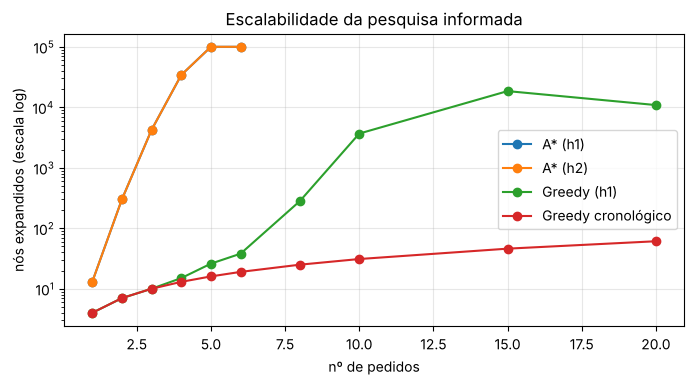

In [5]:
# Sub instâncias com os primeiros k pedidos por ordem de disponibilidade (os mesmos 2 veículos do tiny)
order = sorted(range(P.n), key=lambda r: P.req[r].a)
rows = []
for k in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]:
    Qk = P.subset([P.req[r].id for r in order[:k]])
    algs = [("Greedy cronológico", lambda: greedy_chrono(Qk)),
            ("Greedy (h1)", lambda: best_first(Qk, h_chain, mode="greedy", max_nodes=50000, time_limit=20))]
    if k <= 6:
        algs += [("A* (h1)", lambda: best_first(Qk, h_chain, mode="astar", max_nodes=100000, time_limit=30)),
                 ("A* (h2)", lambda: best_first(Qk, h_disjoint, mode="astar", max_nodes=100000, time_limit=30))]
    for nome, f in algs:
        r = f()
        rows.append(dict(pedidos=k, algoritmo=nome, encontrou=r["found"], nos=r["expanded"], segundos=round(r["seconds"], 2),
                         custo=None if r["cost"] is None else round(r["cost"], 2)))
esc = pd.DataFrame(rows)
print("Nós expandidos:"); display(esc.pivot(index="pedidos", columns="algoritmo", values="nos"))
print("Custo (vazio = não encontrou dentro dos limites):"); display(esc.pivot(index="pedidos", columns="algoritmo", values="custo"))
print("Tempo (s):"); display(esc.pivot(index="pedidos", columns="algoritmo", values="segundos"))
fig, ax = plt.subplots(figsize=(8, 3.8))
for nome, g in esc.groupby("algoritmo"):
    ax.plot(g.pedidos, g.nos, marker="o", label=nome)
ax.set(yscale="log", xlabel="nº de pedidos", ylabel="nós expandidos (escala log)", title="Escalabilidade da pesquisa informada")
ax.grid(alpha=.3); ax.legend(); plt.show()

<p><b>Análise.</b> O A* encontra o ótimo até 4 pedidos, mas o número de nós expandidos multiplica se por cerca de 10 a cada pedido a mais (13, 301, 4239, 34 201) e a partir de 5 pedidos esgota o limite de 100 000 nós. A h1 e a h2 expandem exatamente os mesmos nós: neste dataset as janelas sobrepõem se quase todas e a parte "janelas disjuntas" da h2 não acrescenta informação, ficando só mais cara. O Greedy best first com a h1 é muito mais rápido e chega a 10 pedidos, mas a qualidade cai (entre 10% e 22% acima do ótimo com 2 a 4 pedidos) e falha a partir de 15 pedidos. O Greedy cronológico expande apenas cerca de 3 nós por pedido e escala até ao problema completo, mas as suas soluções são as piores (por exemplo 278.20 contra o ótimo 238.17 com 4 pedidos).</p>

<h2>5. Pesquisa local: Hill Climbing sobre o Greedy</h2>
<p>O Hill Climbing (<code>local_search.hill_climbing</code>) parte da solução completa do Greedy e, por primeira melhoria, aceita o primeiro vizinho viável com custo menor, parando num ótimo local. Os vizinhos (<code>neighbours</code>) são:</p>
<ul>
<li>trocar duas ações de um veículo;</li>
<li>mover uma ação para outra posição ou veículo;</li>
<li>mover a cadeia P, L, D de um pedido;</li>
<li>remover uma ida ao armazém (C);</li>
<li>mover uma paragem inteira (bloco de ações seguidas do mesmo tipo no mesmo local);</li>
<li>mover o par (L, D) de um pedido para uma paragem do armazém de qualquer veículo e uma posição de entrega seguinte. Este movimento foi o que mais melhorou as soluções: permite passar a entrega de um pedido para o outro veículo sem mexer na recolha.</li>
</ul>
<p>As inserções só se fazem nas fronteiras entre paragens (dentro de uma paragem as posições são equivalentes), o que reduz muito o número de vizinhos. Corre se com 5 sementes (ordem aleatória dos vizinhos), até 500 iterações ou 120 s.</p>

In [6]:
# Hill Climbing sobre a solução do Greedy, com 5 sementes (ordem aleatória dos vizinhos)
hc_runs = {s: hill_climbing(P, rt_greedy, seed=s, time_limit=120) for s in range(5)}
pd.DataFrame([dict(semente=s, custo_inicial=round(h["history"][0], 2), custo_final=round(h["cost"], 2),
                   melhoria_pct=round(100 * (1 - h["cost"] / h["history"][0]), 1), iteracoes=len(h["history"]) - 1,
                   vizinhos_avaliados=h["evals"], segundos=round(h["seconds"], 1), paragem=h["stop"]) for s, h in hc_runs.items()])

,semente,custo_inicial,custo_final,melhoria_pct,iteracoes,vizinhos_avaliados,segundos,paragem
0,0,3712.44,627.47,83.1,19,46622,18.2,ótimo local
1,1,3712.44,646.69,82.6,18,23664,9.1,ótimo local
2,2,3712.44,668.14,82.0,17,31785,12.1,ótimo local
3,3,3712.44,691.36,81.4,17,16551,6.1,ótimo local
4,4,3712.44,627.47,83.1,20,28906,10.9,ótimo local


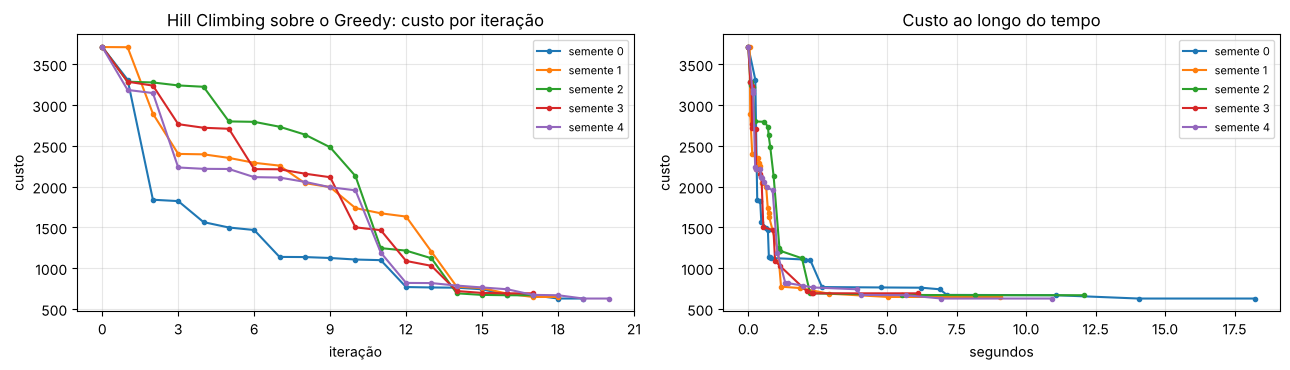

Melhor Hill Climbing: custo 627.47 (627.47 km, 0.0 min de atraso), auditoria ok = True


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for s, h in hc_runs.items():
    ax[0].plot(range(len(h["history"])), h["history"], marker="o", ms=3, label=f"semente {s}")
    ax[1].plot(h["times"], h["history"], marker="o", ms=3, label=f"semente {s}")
ax[0].set(title="Hill Climbing sobre o Greedy: custo por iteração", xlabel="iteração", ylabel="custo")
ax[1].set(title="Custo ao longo do tempo", xlabel="segundos", ylabel="custo")
ax[0].xaxis.set_major_locator(MaxNLocator(integer=True))
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
hc_g = min(hc_runs.values(), key=lambda h: h["cost"])
a = P.audit(hc_g["routes"])
print(f"Melhor Hill Climbing: custo {hc_g['cost']:.2f} ({a['km']:.2f} km, {a['atraso_min']:.1f} min de atraso), auditoria ok = {a['ok']}")

<p><b>Análise.</b> O Hill Climbing melhora a solução do Greedy em mais de 80% em todas as sementes, de 3712.44 para valores entre 627.47 e 691.36, eliminando todo o atraso, em 17 a 20 iterações e 6 a 18 s. As curvas descem em degraus irregulares durante cerca de 14 iterações e depois quase não mudam; em tempo, quase toda a melhoria acontece nos primeiros 2 a 3 s e o resto do tempo é gasto a percorrer vizinhos sem ganho até confirmar o ótimo local. As sementes chegam a ótimos locais diferentes (diferença de 10% entre a melhor e a pior), o que mostra a dependência da ordem dos vizinhos; a melhor solução, 627.47 km sem atrasos, é atingida pelas sementes 0 e 4.</p>

<h2>6. CSP</h2>
<h3>Formulação</h3>
<ul>
<li><b>Variáveis:</b> 4 por pedido, uma por paragem: <b>P</b> (recolha no produtor), <b>C</b> (descarga no armazém pelo veículo que recolheu), <b>L</b> (carga no armazém pelo veículo que vai entregar) e <b>D</b> (entrega). No tiny são 160 variáveis.</li>
<li><b>Domínios:</b> pares (veículo, hora de início), com a hora em passos de 5 min. Os domínios já nascem podados pelas restrições unárias: janela de recolha em P, início da entrega em D, os tempos mínimos de serviço e de viagem em C e L, e só os veículos com capacidade e, se for preciso, refrigerados. O C tem ainda o valor virtual (veículo, sem hora), quando o mesmo veículo recolhe e entrega e a descarga é feita pela própria carga L.</li>
<li><b>Restrições binárias</b> (<code>csp_compatible</code>): P e C no mesmo veículo, com C ≥ P + S + viagem; C virtual obriga L no mesmo veículo; C real obriga L ≥ C + H (fim da descarga) e L ≤ C + H + 24 h; L e D no mesmo veículo, com D ≥ L + H + viagem; no mesmo veículo, duas paragens não se sobrepõem (duração S em P e D, H em C e L, mais a viagem), exceto se forem no mesmo local à mesma hora, que conta como uma só paragem.</li>
<li><b>Restrição global:</b> capacidade de cada veículo ao longo do tempo (<code>capacity_ok</code>).</li>
<li><b>Restrição soft e heurísticas:</b> o domínio de D começa por admitir só o atraso inevitável e é alargado por degraus (0, 15, 30, 60, 120, 480 e 1440 min) até haver solução (<code>csp_complete</code>). Os valores são ordenados pelo <b>menor custo extra</b> (km + 10 × atraso) de inserir a paragem entre a anterior e a seguinte do veículo (<code>incremental_cost</code>): é a heurística que trata a restrição soft.</li>
<li><b>Pesquisa:</b> backtracking com MRV (menos valores legais, desempate pelo grau), forward checking e reinícios aleatórios contra o thrashing. Com <code>optimize=True</code> continua em branch &amp; bound, cortando os ramos cujo custo parcial já ultrapassa a melhor solução.</li>
</ul>
<h3>Atribuição viável no problema completo (tiny)</h3>

In [8]:
csp_full = csp_complete(P, var_order="mrv", value_order="soft", forward_checking=True, time_limit=60)
print(f"Encontrou: {csp_full['found']} | variáveis: {len(csp_full['jobs'])} | nós: {csp_full['nodes']} | backtracks: {csp_full['backtracks']} | "
      f"{csp_full['seconds']:.1f} s | folga de atraso usada: {csp_full.get('max_late_used')} min")
print(f"Custo planeado (grelha de 5 min): {csp_full['cost_planned']:.2f} | custo simulado: {csp_full['cost']:.2f} "
      f"({csp_full['km']:.2f} km, {csp_full['late_min']:.1f} min de atraso)")
print("Auditoria:", {k: v for k, v in P.audit(csp_full["routes"]).items() if k not in ("pedidos_atrasados",)})
assignment_table(P, csp_full, origin).head(12)

Encontrou: True | variáveis: 160 | nós: 1797 | backtracks: 1637 | 5.3 s | folga de atraso usada: 0 min
Custo planeado (grelha de 5 min): 819.83 | custo simulado: 819.83 (819.83 km, 0.0 min de atraso)
Auditoria: {'ok': True, 'problemas': [], 'km': 819.8299999999999, 'atraso_min': 0.0, 'custo': 819.8299999999999, 'carga_max_kg': [48.9, 163.1], 'max_armazem_h': 22.51}


,variavel,pedido,veiculo,inicio
0,P_1,1,2,31/10 08:00
1,C_1,1,2,NaN
2,L_1,1,2,31/10 09:55
3,D_1,1,2,31/10 12:45
4,P_2,2,2,31/10 09:00
5,C_2,2,2,NaN
6,L_2,2,2,31/10 09:55
7,D_2,2,2,31/10 12:45
8,P_3,3,1,31/10 09:25
9,C_3,3,1,NaN


<p>O CSP encontra uma <b>atribuição viável para os 40 pedidos</b> (160 variáveis) com <b>1797 nós e 1637 backtracks</b>, em cerca de 6 s, logo com a folga de atraso 0: nenhum pedido se atrasa. O custo é 819.83 km, a auditoria confirma todas as restrições hard e o tempo máximo de um produto no armazém é de 22.5 h, perto do limite de 24 h. A tabela mostra as primeiras variáveis da atribuição: por exemplo, o pedido 1 é recolhido, carregado e entregue pelo veículo 2, com a descarga virtual (C sem hora).</p>

<h3>Efeito das heurísticas (sub instância com 10 pedidos)</h3>
<p>Comparam se a ordem das variáveis (estática ou MRV), a ordem dos valores (lexicográfica ou menor custo extra) e o forward checking (FC), sem reinícios e com 10 s por configuração.</p>

In [9]:
Q10 = P.subset([P.req[r].id for r in order[:10]])
rows = []
for var_order in ("static", "mrv"):
    for value_order in ("lex", "soft"):
        for fc in (False, True):
            r = csp_solve(Q10, var_order=var_order, value_order=value_order, forward_checking=fc, time_limit=10, restarts=0)
            rows.append(dict(variaveis=var_order, valores=value_order, FC=fc, encontrou=r["found"], nos=r["nodes"],
                             backtracks=r["backtracks"], custo=None if r["cost"] is None else round(r["cost"], 2), segundos=round(r["seconds"], 2)))
pd.DataFrame(rows)

,variaveis,valores,FC,encontrou,nos,backtracks,custo,segundos
0,static,lex,False,True,38546,38506,480.28,0.37
1,static,lex,True,True,944,904,480.28,0.11
2,static,soft,False,False,300009,299977,NaN,2.52
3,static,soft,True,True,507,467,456.30,0.12
4,mrv,lex,False,False,300140,300120,NaN,1.48
5,mrv,lex,True,True,40,0,267.48,0.09
6,mrv,soft,False,False,300189,300169,NaN,2.04
7,mrv,soft,True,True,40,0,267.48,0.10


<p><b>Análise.</b> O forward checking é decisivo: sem ele, três das quatro combinações esgotam os 300 000 nós sem solução, e a única que encontra (estática + lexicográfica) precisa de 38 546 nós. Com FC, a MRV encontra uma solução em 40 nós e 0 backtracks. A ordem dos valores "soft" melhora a solução da ordem estática (480.28 para 456.30); com MRV as duas ordens dão a mesma solução (267.48), a melhor da tabela.</p>

<h3>Branch &amp; bound</h3>
<p>Em sub instâncias de 4, 6 e 8 pedidos, compara se a primeira solução com o branch &amp; bound (20 s), e com o ótimo do A* quando existe.</p>

In [10]:
ref = esc[esc.algoritmo == "A* (h1)"].set_index("pedidos").custo
rows = []
for k in (4, 6, 8):
    Qk = P.subset([P.req[r].id for r in order[:k]])
    a = csp_solve(Qk, var_order="mrv", value_order="soft", forward_checking=True, time_limit=20)
    b = csp_solve(Qk, var_order="mrv", value_order="soft", forward_checking=True, optimize=True, time_limit=20)
    rows.append(dict(pedidos=k, primeira=a["cost"] and round(a["cost"], 2), nos_primeira=a["nodes"], bt_primeira=a["backtracks"],
                     otimizado=b["cost"] and round(b["cost"], 2), nos_otimizado=b["nodes"], seg_otimizado=round(b["seconds"], 1),
                     esgotou=b["complete"], otimo_A=ref.get(k)))
pd.DataFrame(rows)

,pedidos,primeira,nos_primeira,bt_primeira,otimizado,nos_otimizado,seg_otimizado,esgotou,otimo_A
0,4,261.73,17,1,261.73,45991,20.0,False,238.17
1,6,336.95,41,17,336.95,13542,20.1,False,NaN
2,8,250.83,32,0,250.83,12508,20.1,False,NaN


<p><b>Análise.</b> Em 20 s o branch &amp; bound não melhora a primeira solução e não esgota a árvore em nenhuma das três sub instâncias. Com 4 pedidos fica em 261.73, 10% acima do ótimo do A* (238.17). Há duas razões: a grelha de 5 min cria muitas soluções equivalentes (a mesma rota 5 min mais cedo ou mais tarde) e o limite inferior (custo das paragens já atribuídas) é fraco; além disso, a formulação é mais restrita do que o modelo de estados (horas múltiplas de 5 min, capacidade conservadora), por isso o ótimo do CSP pode estar acima do ótimo do modelo.</p>

<h3>Hill Climbing sobre a solução do CSP</h3>
<p>Como termo de comparação, aplica se o mesmo Hill Climbing à solução do CSP.</p>

In [11]:
hc_c = hill_climbing(P, csp_full["routes"], seed=0, time_limit=120)
print(f"Hill Climbing sobre o CSP: {hc_c['history'][0]:.2f} -> {hc_c['cost']:.2f} em {len(hc_c['history']) - 1} iterações, "
      f"{hc_c['seconds']:.1f} s ({hc_c['stop']})")

Hill Climbing sobre o CSP: 819.83 -> 630.59 em 11 iterações, 9.8 s (ótimo local)


<h2>7. Análise de resultados</h2>
<h3>Melhor solução: agente completo no tiny</h3>
<p>O agente (<code>agent.solve_all</code>) divide o problema em grupos temporais (aqui um só), constrói a solução com o Greedy cronológico, melhora a com o Hill Climbing e valida o plano final com <code>audit</code>.</p>

In [12]:
t0 = time.time()
routes, info, audit = solve_all(P, hc_time=120)
t_agent = time.time() - t0
print(f"Agente completo (Greedy + Hill Climbing): {t_agent:.1f} s")
display(pd.DataFrame(info))
print({k: v for k, v in audit.items() if k != "pedidos_atrasados"})
tl = P.timeline(routes, origin)
tl.groupby("veiculo").agg(acoes=("acao", "count"), km=("km", "sum"), atraso_min=("atraso_min", "sum"), carga_max_kg=("carga_kg", "max")).round(1)

Agente completo (Greedy + Hill Climbing): 18.7 s


,pedidos,found,custo_inicial,custo,hc_iter,hc_seg,hc_paragem
0,40,True,3712.44,627.47,19,18.6,ótimo local


{'ok': True, 'problemas': [], 'km': 627.4699999999999, 'atraso_min': 0.0, 'custo': 627.4699999999999, 'carga_max_kg': [115.5, 166.9], 'max_armazem_h': 0.02}


,acoes,km,atraso_min,carga_max_kg
veiculo,,,,
1,43,235.1,0.0,115.5
2,79,392.4,0.0,166.9


In [13]:
# Cronograma por paragem (uma linha por paragem: ações seguidas do mesmo veículo no mesmo local e à mesma hora)
tls = tl[tl.acao != "R"].sort_values(["veiculo", "inicio"], kind="stable")
stops = (tls.assign(paragem=(tls[["veiculo", "local", "inicio"]] != tls[["veiculo", "local", "inicio"]].shift()).any(axis=1).cumsum())
           .groupby("paragem").agg(veiculo=("veiculo", "first"), acao=("acao", "first"), local=("local", "first"),
                                   pedidos=("pedido", lambda s: ", ".join(str(x) for x in s.dropna())),
                                   inicio=("hora_inicio", "first"), fim=("hora_fim", "first"), km=("km", "sum"),
                                   atraso_min=("atraso_min", "sum"), carga_kg=("carga_kg", "last")))
print(len(tls), "ações em", len(stops), "paragens (sem contar o regresso ao centro)")
stops

120 ações em 31 paragens (sem contar o regresso ao centro)


,veiculo,acao,local,pedidos,inicio,fim,km,atraso_min,carga_kg
paragem,,,,,,,,,
1,1,L,4,"26, 29",30/10 10:47,30/10 11:02,0.00,0.0,12.4
2,1,P,3,9,31/10 06:45,31/10 06:55,29.06,0.0,15.5
3,1,P,3,14,31/10 07:00,31/10 07:10,0.00,0.0,20.0
4,1,P,3,4,31/10 07:15,31/10 07:25,0.00,0.0,27.1
5,1,P,3,3,31/10 07:30,31/10 07:40,0.00,0.0,32.0
6,1,P,3,"8, 17",31/10 07:45,31/10 07:55,0.00,0.0,44.5
7,1,P,2,"1, 7, 15, 16, 18",31/10 08:29,31/10 08:39,26.05,0.0,74.4
8,1,P,1,"2, 10, 19, 20, 21",31/10 09:11,31/10 09:21,23.59,0.0,115.5
9,1,D,9,"26, 29",31/10 09:40,31/10 09:50,14.86,0.0,103.1


<p>O plano final serve os <b>40 pedidos</b> com <b>627.47 km e nenhum atraso</b> (custo 627.47), passa a auditoria e demora cerca de 18 s. As 120 ações (sem o regresso ao centro) agrupam se em 31 paragens: o serviço por paragem compensa, porque um veículo recolhe até 8 pedidos de uma vez no mesmo produtor e entrega até 5 de uma vez. A carga máxima é de 115.5 kg e 166.9 kg, abaixo das capacidades (150 e 200 kg). O veículo 2 faz a maior parte do trabalho do dia 30; o veículo 1 carrega a 30/10 dois pedidos que só entrega a 31/10 (o tempo a bordo não está limitado no modelo; ver limitações).</p>
<p><b>Mapa das rotas</b> por veículo e por dia (círculo = produtor, estrela = centro, quadrado = local de entrega; a/b = pontos com as mesmas coordenadas).</p>

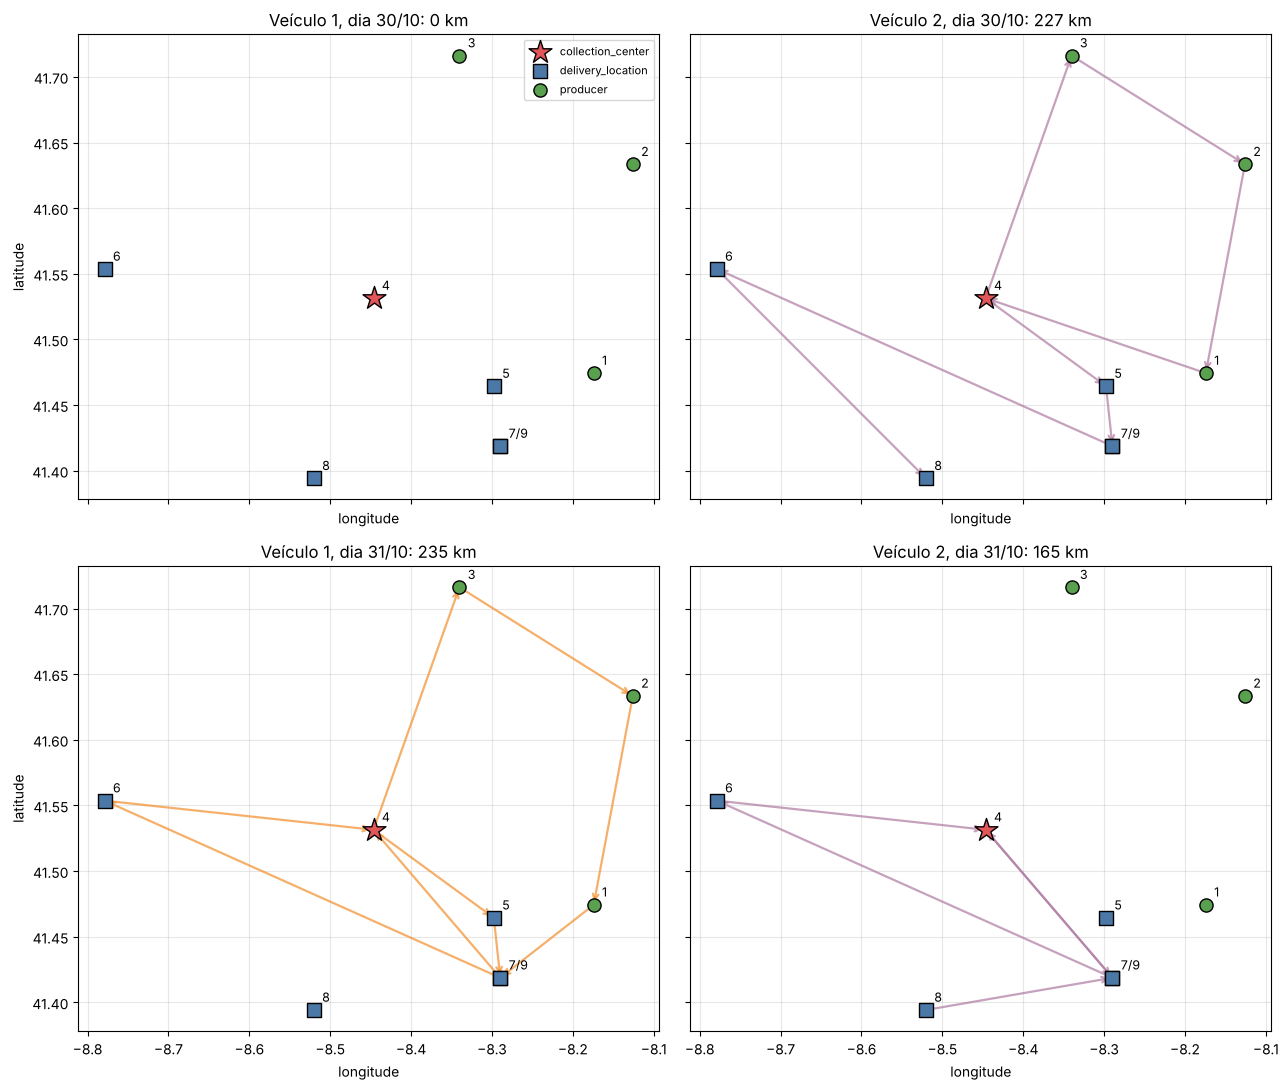

In [14]:
loc = pd.read_csv(f"{DATA}/locations.csv").set_index("location_id")
cor_tipo = {"producer": "#59a14f", "collection_center": "#e15759", "delivery_location": "#4c78a8"}
marca = {"producer": "o", "collection_center": "*", "delivery_location": "s"}
cores_v = ["#f28e2b", "#af7aa1"]
fig, axs = plt.subplots(2, P.K, figsize=(6.5 * P.K, 11), sharex=True, sharey=True)
for d, dia in enumerate(sorted(tl.hora_inicio.str[:5].unique())):
    for v in range(P.K):
        ax = axs[d][v]
        for tp, g in loc.groupby("location_type"):
            ax.scatter(g.longitude, g.latitude, c=cor_tipo[tp], marker=marca[tp], s=300 if tp == "collection_center" else 90,
                       edgecolor="k", zorder=4 if tp == "collection_center" else 3, label=tp)
        for (la, lo), g in loc.groupby(["latitude", "longitude"]):
            ax.annotate("/".join(map(str, g.index)), (lo, la), textcoords="offset points", xytext=(6, 6), fontsize=9)
        vid = P.veh[v].id
        sub = tl[(tl.veiculo == vid) & (tl.hora_inicio.str[:5] == dia)]
        prev = tl[(tl.veiculo == vid) & (tl.hora_inicio.str[:5] < dia)]
        seq = [prev.local.iloc[-1] if len(prev) else P.veh[v].center] + list(sub.local)
        for a_, b_ in zip(seq, seq[1:]):
            if a_ != b_:
                ax.annotate("", xy=(loc.longitude[b_], loc.latitude[b_]), xytext=(loc.longitude[a_], loc.latitude[a_]),
                            arrowprops=dict(arrowstyle="->", color=cores_v[v % 2], alpha=0.7, lw=1.6), zorder=2)
        ax.set(title=f"Veículo {vid}, dia {dia}: {sub.km.sum():.0f} km", xlabel="longitude"); ax.grid(alpha=.3)
axs[0][0].legend(fontsize=8); axs[0][0].set_ylabel("latitude"); axs[1][0].set_ylabel("latitude")
plt.tight_layout(); plt.show()

<h3>Comparação no problema completo (tiny)</h3>

In [15]:
comp = pd.DataFrame([
    dict(metodo="Greedy cronológico", custo=g_full["cost"], km=g_full["km"], atraso_min=g_full["late_min"], segundos=g_full["seconds"], prova_otimo=False),
    dict(metodo="Hill Climbing sobre o Greedy (melhor de 5 sementes)", custo=hc_g["cost"], km=P.audit(hc_g["routes"])["km"],
         atraso_min=P.audit(hc_g["routes"])["atraso_min"], segundos=g_full["seconds"] + hc_g["seconds"], prova_otimo=False),
    dict(metodo="CSP (MRV + FC + valores soft), 1.ª solução", custo=csp_full["cost"], km=csp_full["km"], atraso_min=csp_full["late_min"],
         segundos=csp_full["seconds"], prova_otimo=False),
    dict(metodo="Hill Climbing sobre o CSP", custo=hc_c["cost"], km=P.audit(hc_c["routes"])["km"], atraso_min=P.audit(hc_c["routes"])["atraso_min"],
         segundos=csp_full["seconds"] + hc_c["seconds"], prova_otimo=False),
    dict(metodo="Agente completo (solve_all)", custo=audit["custo"], km=audit["km"], atraso_min=audit["atraso_min"], segundos=t_agent, prova_otimo=False),
    dict(metodo="A* (h1 ou h2)", custo=None, km=None, atraso_min=None, segundos=None, prova_otimo=True),
]).round(2)
comp["acima_do_melhor_%"] = ((comp.custo / comp.custo.min() - 1) * 100).round(1)
comp

,metodo,custo,km,atraso_min,segundos,prova_otimo,acima_do_melhor_%
0,Greedy cronológico,3712.44,854.44,285.8,0.11,False,491.7
1,Hill Climbing sobre o Greedy (melhor de 5 seme...,627.47,627.47,0.0,18.34,False,0.0
2,"CSP (MRV + FC + valores soft), 1.ª solução",819.83,819.83,0.0,5.33,False,30.7
3,Hill Climbing sobre o CSP,630.59,630.59,0.0,15.14,False,0.5
4,Agente completo (solve_all),627.47,627.47,0.0,18.75,False,0.0
5,A* (h1 ou h2),NaN,NaN,NaN,NaN,True,NaN


<h3>Dataset small (80 pedidos)</h3>

In [16]:
Ps, origin_s = load_problem(DATA_SMALL, verbose=True)
print("Grupos temporais:", [len(g) for g in temporal_groups(Ps)])
g_s = greedy_chrono(Ps)
print(f"Greedy cronológico: {g_s['expanded']} nós, {g_s['seconds']:.2f} s, custo {g_s['cost']:.2f}")
c_s = csp_complete(Ps, var_order="mrv", value_order="soft", forward_checking=True, time_limit=30)
print(f"CSP (30 s): encontrou = {c_s['found']}, {c_s['nodes']} nós, {c_s['backtracks']} backtracks")
t0 = time.time()
routes_s, info_s, audit_s = solve_all(Ps, hc_time=180)
t_small = time.time() - t0
print(f"Agente completo no small: {t_small:.1f} s")
display(pd.DataFrame(info_s))
print({k: v for k, v in audit_s.items() if k != "pedidos_atrasados"})
tl_s = Ps.timeline(routes_s, origin_s)
tl_s.groupby("veiculo").agg(acoes=("acao", "count"), km=("km", "sum"), atraso_min=("atraso_min", "sum"), carga_max_kg=("carga_kg", "max")).round(1)

Dataset data_small: regras de data_small/rules.csv
  S = 10 min por paragem, H = 15 min no armazém, máximo no armazém = 24 h, janelas sobre o início do serviço
  origem do tempo: 2026-10-30 00:00:00
  80 pedidos (25 encomendas, 580.0 kg), 2 veículos [1: 250 kg, refrigerado], [2: 300 kg], centro = location 7, pedidos que exigem frio: 0
Grupos temporais: [80]


Greedy cronológico: 241 nós, 0.81 s, custo 3215.86


CSP (30 s): encontrou = False, 6655 nós, 6242 backtracks


Agente completo no small: 96.7 s


,pedidos,found,custo_inicial,custo,hc_iter,hc_seg,hc_paragem
0,80,True,3215.86,1004.22,20,96.0,ótimo local


{'ok': True, 'problemas': [], 'km': 1004.2200000000001, 'atraso_min': 0.0, 'custo': 1004.2200000000001, 'carga_max_kg': [217.6, 173.3], 'max_armazem_h': 21.55}


,acoes,km,atraso_min,carga_max_kg
veiculo,,,,
1,153,574.8,0.0,217.6
2,89,429.4,0.0,173.3


<p>No small, o Greedy cronológico encontra uma solução em 241 nós e menos de 1 s (custo 3215.86) e o Hill Climbing reduz a para <b>1004.22 km sem atrasos</b>, em cerca de 100 s; o plano serve os 80 pedidos e passa a auditoria. A carga máxima (217.6 e 173.3 kg) respeita as capacidades e o tempo máximo de um produto no armazém é de 21.55 h, abaixo das 24 h. O CSP não encontra solução em 30 s: com 320 variáveis e domínios largos (os pedidos do dia seguinte), o backtracking perde se em thrashing mesmo com reinícios.</p>

<h3>Análise crítica</h3>
<ul>
<li><b>Melhores soluções:</b> tiny, 627.47 km sem atrasos (Hill Climbing sobre o Greedy); small, 1004.22 km sem atrasos. Não há prova de ótimo: o A* só prova o ótimo até 4 pedidos.</li>
<li><b>Tempos:</b> Greedy cronológico, 0.1 s (tiny) e 0.8 s (small); CSP, cerca de 6 s no tiny e sem solução em 30 s no small; Hill Climbing, 6 a 18 s no tiny e cerca de 100 s no small; A*, impraticável acima de 4 pedidos. O notebook completo demora cerca de 8 a 9 min.</li>
<li><b>Comparação:</b> o A* é ótimo mas não escala. O Greedy cronológico escala, mas dá soluções más (491.7% acima da melhor no tiny, quase tudo penalização de atraso). O CSP é o único método construtivo que chega a uma solução sem atrasos no tiny (30.7% acima da melhor), mas não escala para o small. O Hill Climbing é o que mais acrescenta: a partir do Greedy ou do CSP chega a soluções quase iguais (627.47 e 630.59), o que sugere que estão perto de um bom ótimo local.</li>
<li><b>Heurísticas:</b> a h2 não trouxe vantagem nestes datasets; a h3 também não guiou o Greedy best first até uma solução, o que levou ao Greedy cronológico.</li>
<li><b>Mudança face ao dataset antigo:</b> deixou de haver grupos independentes e de haver atrasos inevitáveis; a dificuldade passou da otimização de grupos pequenos para a construção de uma solução viável com muitos pedidos.</li>
</ul>
<h3>Limitações</h3>
<ul>
<li>O tempo a bordo de um veículo não está limitado: um produto pode ser carregado num dia e entregue no dia seguinte sem contar para as 24 h do armazém.</li>
<li>A capacidade do centro e a refrigeração não estão ativas nestes dados (a refrigeração está implementada, mas nenhum produto a exige).</li>
<li>O CSP usa uma grelha de 5 min e uma capacidade conservadora, por isso pode rejeitar planos que o modelo de estados aceita.</li>
<li>O Hill Climbing depende da semente e da solução inicial; não prova otimalidade.</li>
</ul>
<h3>Melhorias futuras</h3>
<ul>
<li>Limitar o tempo a bordo (frescura dos produtos) e ativar a refrigeração quando os dados a indicarem.</li>
<li>Usar a velocidade de cada veículo (escalar os tempos da matriz por veículo) e vários centros de recolha.</li>
<li>Hill Climbing com reinícios aleatórios, Simulated Annealing ou pesquisa tabu, para escapar aos ótimos locais.</li>
<li>A* com heurísticas mais fortes (por exemplo baseadas em árvores de cobertura mínima) ou variantes com memória limitada, e uma decomposição por dia com ligação entre dias.</li>
<li>CSP com propagação mais forte (arc consistency, AC-3), quebra de simetrias da grelha de tempo e um limite inferior melhor no branch &amp; bound, para escalar ao small.</li>
<li>Replaneamento dinâmico quando entram pedidos novos.</li>
</ul>

<h2>8. Conclusão</h2>
<p>O agente planeia rotas que servem todos os pedidos dos dois datasets novos sem atrasos e cumprindo todas as restrições obrigatórias: <b>627.47 km no tiny</b> (40 pedidos) e <b>1004.22 km no small</b> (80 pedidos), verificados pelo <code>audit</code>. A adaptação ao <code>rules.csv</code> mudou o modelo em pontos importantes: serviço por paragem, manuseamento de 15 min no armazém, limite de 24 h, origem do tempo em 30/10 e suporte para refrigeração, e cada interpretação ficou documentada.</p>
<p><b>Balanço dos algoritmos.</b> O A* é ótimo mas só resolve sub instâncias até 4 pedidos, com a h1 e a h2 a expandirem os mesmos nós. O Greedy best first falhou no problema completo, e o Greedy cronológico foi a forma de obter sempre uma solução completa, em décimas de segundo, ainda que com muitos atrasos. O Hill Climbing sobre essa solução foi o passo decisivo, com melhorias acima de 80%. O CSP com MRV, forward checking e valores ordenados pelo custo extra encontrou uma atribuição viável e sem atrasos no tiny, mas não escalou ao small; o forward checking mostrou se indispensável.</p>
<p><b>Desenvolvimento e ferramentas.</b> O projeto foi feito em Python (pandas e numpy para os dados e o modelo, matplotlib para os gráficos) e Jupyter Notebook, com o código separado em módulos (<code>model.py</code>, <code>informed.py</code>, <code>local_search.py</code>, <code>csp.py</code>, <code>agent.py</code>) e versionado no GitHub. A principal lição foi que, com dados novos e mais densos no tempo, a parte mais difícil deixou de ser otimizar e passou a ser construir uma primeira solução viável; separar o modelo (regras, simulador e verificador) dos algoritmos permitiu mudar as regras sem reescrever os algoritmos.</p>

In [17]:
print(f"Tempo total de execução do notebook: {(time.time() - T0) / 60:.1f} min")

Tempo total de execução do notebook: 8.3 min
